### TEL354 - Minería de datos
# Clase 5: Dimensionality Reduction
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

In [1]:
from Clase5 import *

# Dimensionality Reduction

<div align="center">
<img src="img/dimensionality_reduction.png" alt="" width="30%" align="center" />
</div>

La reducción de dimensionalidad de un conjunto de datos puede traer varios beneficios:

* Reducir el tiempo de entrenamiento, disminuir la memoria necesaria y mejorar el rendimiento de los algoritmos de ML.
* Eliminar atributos irrelevantes y reducir el número de atributos ruidosos.
* Hacer que la visualización de datos sea más fácil de entender y permitir la visualización de conjuntos de datos con un gran número de atributos.

# Principal Component Analysis

El análisis de componentes principales es un método no supervisado rápido y flexible para la reducción de la dimensionalidad de los datos. PCA es rápido y eficiente, pero asume que las relaciones entre las variables son lineales.

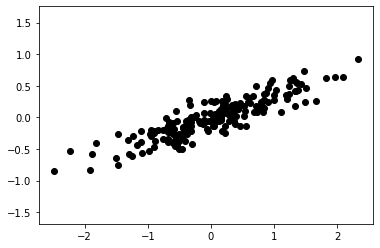

In [2]:
rng = np.random.RandomState(1)
X = np.dot(rng.rand(2, 2), rng.randn(2, 200)).T
plt.scatter(X[:, 0], X[:, 1], c='k')
plt.axis('equal')
plt.show()

## ¿Qué busca PCA?

PCA busca nuevas dimensiones donde los datos:

- tengan la **máxima varianza posible**
- estén **descorrelacionados**
- permitan representar mejor la estructura de los datos

En lugar de usar los ejes originales ($x_1$, $x_2$, $\dots$), PCA encuentra **nuevos ejes rotados** que se ajustan a los datos.

In [3]:
pca = PCA(n_components=2).fit(X)

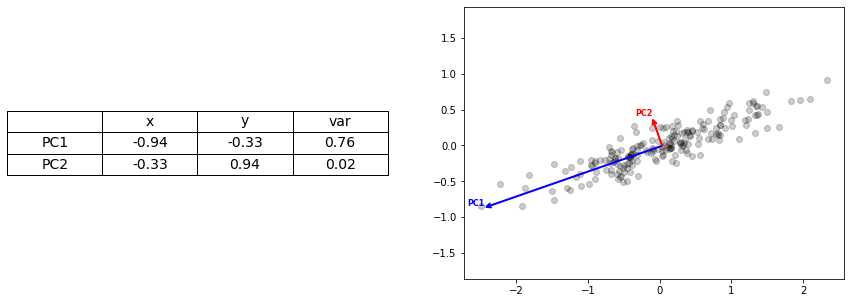

In [4]:
demo_pca(X, pca)

### Componentes principales

- **PC1**: dirección de mayor varianza
- **PC2**: dirección ortogonal con mayor varianza restante

## The projection

La transformación lineal que ejerce PCA implica proyectar cada punto de los datos sobre los componentes principales.

In [5]:
X_pca = pca.fit_transform(X)

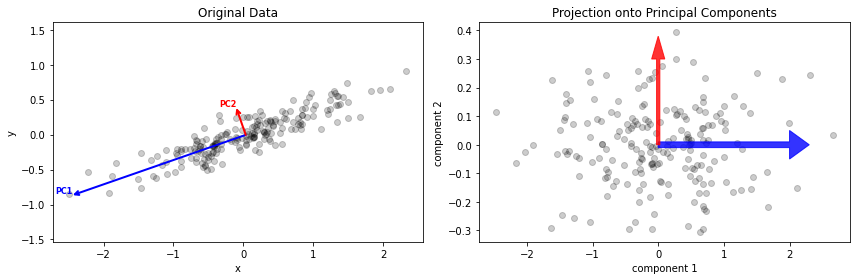

In [6]:
plot_projection(X, X_pca, pca, axis_equal=False)

## ¿De dónde salen los componentes principales?

**No son arbitrarios:** Se calculan a partir de la estructura de los datos

### Pasos conceptuales:

1. Centrar los datos (media = 0)
2. Analizar cómo varían las variables juntas
3. Encontrar direcciones donde la varianza es máxima

Esas direcciones son los **componentes principales**

## ¿Cómo se calcula PCA?

1. Centrar los datos
2. Calcular la **matriz de covarianza**
3. Obtener:

    - **Autovectores (eigenvectors)** → direcciones
    - **Autovalores (eigenvalues)** → importancia

### Resultado

- Los componentes principales son los **autovectores**

- La importancia de cada componente viene dada por su **varianza explicada**

## ¿Qué es la covarianza?

Mide cómo varían dos variables juntas

### Casos:

- Cov > 0 → crecen juntas
- Cov < 0 → una sube, otra baja
- Cov ≈ 0 → no están relacionadas

Indica la **dirección de relación entre variables**

## Matriz de covarianza

Resume la relación entre TODAS las variables

Ejemplo (3 variables):

|      | x₁ | x₂ | x₃ |
|------|----|----|----|
| x₁ | var | cov | cov |
| x₂ | cov | var | cov |
| x₃ | cov | cov | var |

- La diagonal = varianza  
- Fuera de diagonal = relación entre variables

## Autovectores y autovalores

Dada la matriz de covarianza $A$, buscamos vectores que cumplen: $A v = λ v$

- **Autovectores** = direcciones importantes  
- **Autovalores** = cuánta varianza hay en esa dirección

Conexión con PCA:

- Autovectores → componentes principales
- Autovalores → varianza explicada

## Interpretación clave

Cada componente principal es: una **combinación lineal de las variables originales**

Ejemplo:

$PC1 = 0.5\cdot x_1 + 0.3\cdot x_2 + 0.8\cdot x_3 + \dots$

Esto significa:

- NO estamos eliminando variables
- Estamos **re-expresando los datos en un nuevo sistema de coordenadas**

# PCA as dimensionality reduction

El uso de PCA para la reducción de dimensionalidad implica mantener solo los componentes principales más grandes (con $\text{n_components} << \text{dim}$), lo que da como resultado una proyección de menor dimensión de los datos que preserva la mayor varianza posible.

In [7]:
pca = PCA(n_components=1).fit(X)
X_pca = pca.transform(X)
print("original shape: ", X.shape)
print("transformed shape:", X_pca.shape)

original shape:  (200, 2)
transformed shape: (200, 1)


## Visualization of PCA as dimensionality reduction

Los datos transformados se han reducido a una única dimensión. Para comprender el efecto de esta reducción de dimensionalidad, podemos realizar la transformación inversa de estos datos reducidos y trazarlos junto con los datos originales.

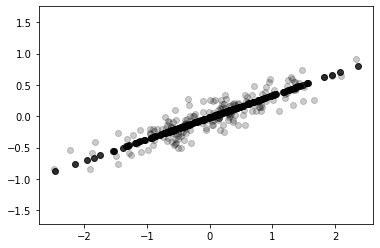

In [8]:
X_new = pca.inverse_transform(X_pca)
plt.scatter(X[:, 0], X[:, 1], alpha=0.2, c='k')
plt.scatter(X_new[:, 0], X_new[:, 1], alpha=0.8, c='k')
plt.axis('equal')
plt.show()

# PCA for visualization: Handwritten digits

In [9]:
digits = load_digits()

In [10]:
X_digits = digits.data
y_digits = digits.target

In [11]:
X_digits

array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ..., 10.,  0.,  0.],
       [ 0.,  0.,  0., ..., 16.,  9.,  0.],
       ...,
       [ 0.,  0.,  1., ...,  6.,  0.,  0.],
       [ 0.,  0.,  2., ..., 12.,  0.,  0.],
       [ 0.,  0., 10., ..., 12.,  1.,  0.]])

In [12]:
X_digits.shape

(1797, 64)

In [13]:
X_digits[0]

array([ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
       15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
       12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
        0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
       10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.])

In [14]:
X_digits[0].reshape(8,8)

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
       [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
       [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
       [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
       [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
       [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
       [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
       [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]])

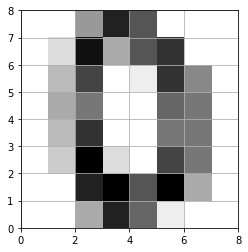

In [15]:
plt.imshow(X_digits[0].reshape(8,8), cmap=plt.cm.binary, extent=(0, 8, 8, 0))
plt.grid()
plt.xlim(0,8)
plt.ylim(0,8)
plt.show()

## Etiquetas reales

In [16]:
y_digits

array([0, 1, 2, ..., 8, 9, 8])

In [17]:
y_digits.shape

(1797,)

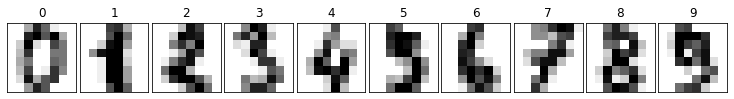

In [18]:
plot_digits(X_digits, y_digits)

In [19]:
pca = PCA(2)
projected_pca = pca.fit_transform(X_digits)

In [20]:
projected_pca

array([[ -1.25946444,  21.27488344],
       [  7.95761838, -20.76869128],
       [  6.99191595,  -9.95599255],
       ...,
       [ 10.80128217,  -6.96025438],
       [ -4.8720952 ,  12.4239575 ],
       [ -0.34439633,   6.36554227]])

In [21]:
projected_pca.shape

(1797, 2)

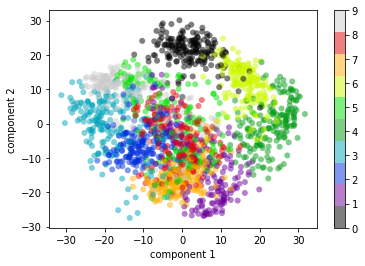

In [22]:
cmap_discrete = ListedColormap(plt.cm.nipy_spectral(np.linspace(0, 1, 10)))
plt.scatter(projected_pca[:, 0], projected_pca[:, 1], 
            c=digits.target, edgecolor='none', alpha=0.5, 
            cmap=cmap_discrete)
plt.xlabel('component 1')
plt.ylabel('component 2')
plt.colorbar()
plt.show()

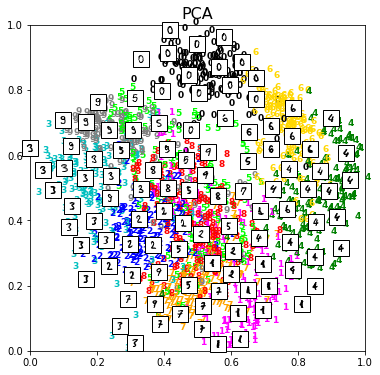

In [23]:
plot_embedding(projected_pca, digits, "PCA")

# What do the components mean?

Para empezar a preguntarnos qué significan las dimensiones reducidas podemos imaginar combinaciones de vectores básicos. Por ejemplo, cada imagen en el conjunto de entrenamiento está definida por una colección de valores de 64 píxeles, que llamaremos vector $x$:

$$ x = [x_1, x_2, x_3 \cdots x_{64}] $$

Si pensamos esto en términos de píxeles, para construir una imagen multiplicamos cada elemento del vector por el píxel y luego sumamos los resultados:

$$ \text{image}(x) = x_1 \cdot (\text{pixel 1}) + x_2 \cdot (\text{pixel 2}) + \cdots + x_{64} \cdot (\text{pixel 64})  $$



## A naive dimensionality reduction achieved by discarding pixels

Por lo tanto, una forma ingenua para reducir la dimensión es llevar a cero todos menos algunos de estos vectores base. Por ejemplo, si utilizamos sólo los primeros ocho píxeles, obtenemos una proyección de los datos en ocho dimensiones (aunque no refleja mucho la imagen completa, ya que hemos desechado casi el 90% de los píxeles!).

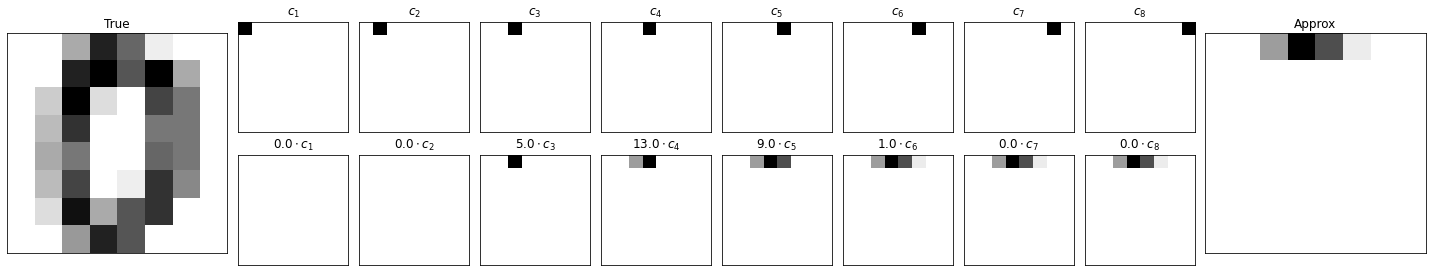

In [24]:
naive_dimensionality_reduction(X_digits)

## PCA basis functions

Una reducción de dimensionalidad más sofisticada se logra descartando los componentes principales menos importantes.

$$ \text{image}(x) = \text{mean} + x_1 \cdot (\text{basis 1}) + x_2 \cdot (\text{basis 2}) + x_3 \cdot (\text{basis 3}) \cdots $$

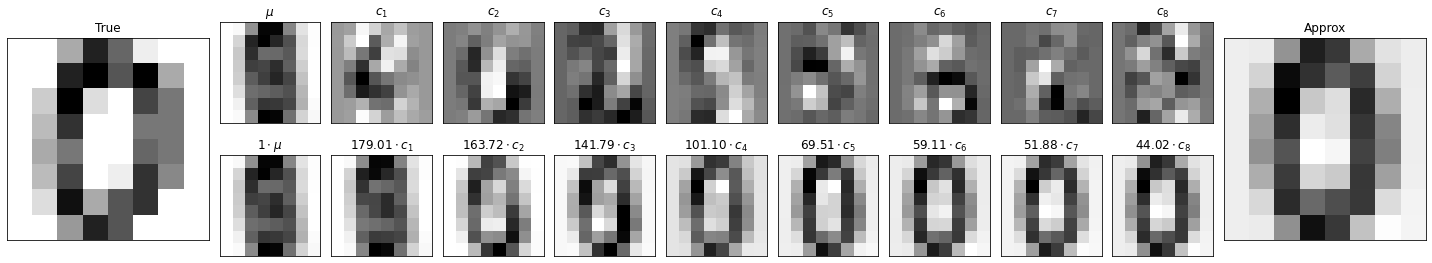

In [25]:
PCA_basis_functions(X_digits)

# Choosing the number of components

Una parte vital del uso de PCA en la práctica es la capacidad de estimar cuántos componentes se necesitan para describir los datos. Podemos determinar esto observando el índice de varianza explicada acumulada en función del número de componentes. Esta curva cuantifica qué parte de la varianza total está contenida dentro de los primeros N componentes. Por ejemplo, vemos que los primeros 10 componentes contienen ~75% de la varianza, mientras que se necesitan ~50 componentes para llegar al 100%.

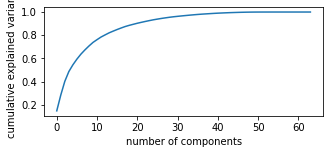

In [26]:
plt.figure(figsize = (5,2))
pca = PCA().fit(digits.data)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('number of components'); plt.ylabel('cumulative explained variance');

# PCA as Noise Filtering

PCA también se puede utilizar como método de filtrado para datos ruidosos. La idea es la siguiente: cualquier componente con una variación mucho mayor que el efecto del ruido no debería verse relativamente afectado por el ruido. Entonces, si reconstruye los datos utilizando solo el subconjunto más grande de componentes principales, preferiblemente debería mantener la señal y eliminar el ruido.

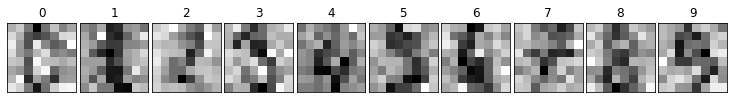

In [27]:
np.random.seed(42)
noisy = np.random.normal(digits.data, 4)
plot_digits(noisy, digits.target)

## Reconstrucción

Entrenemos a un PCA con los datos ruidosos, solicitando que la proyección conserve el 50% de la varianza. Aquí el 50% de la variación equivale a 12 componentes principales. Luego calculamos estos componentes y usamos la inversa de la transformación para reconstruir los dígitos filtrados.

In [28]:
pca = PCA(0.50).fit(noisy)
pca.n_components_

12

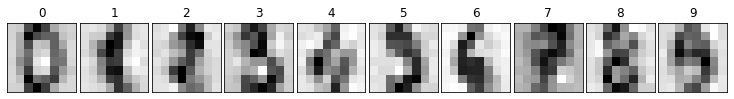

In [29]:
components = pca.transform(noisy)
filtered = pca.inverse_transform(components)
plot_digits(filtered, digits.target)

# Example: Eigenfaces

In [30]:
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(faces.images.shape)
print("Dim:",faces.images.shape[1]*faces.images.shape[2])

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
(1348, 62, 47)
Dim: 2914


## A visualization of eigenfaces learned from the LFW dataset

Los vectores principales parecen estar asociadas con el ángulo de iluminación de la cara y ciertas características, como ojos, narices y labios.

In [31]:
pca = PCA(150).fit(faces.data)

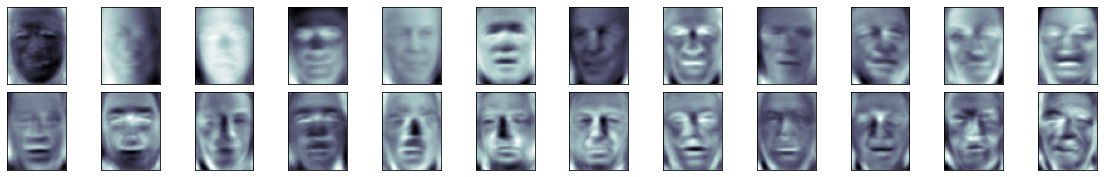

In [32]:
fig, axes = plt.subplots(2, 12, figsize=(20, 3), 
                         subplot_kw={'xticks':[], 'yticks':[]}, 
                         gridspec_kw=dict(hspace=0.1, wspace=0.1))
for i, ax in enumerate(axes.flat):
    ax.imshow(pca.components_[i].reshape(62, 47), cmap='bone')

## Varianza acumulada

Cuando echamos un vistazo a la varianza acumulada de estos componentes para ver cuánta información de datos preserva la proyección, vemos que estos 150 componentes representan poco más del 90% de la varianza. Por lo tanto, con 150 componentes recuperamos la mayoría de las características esenciales.

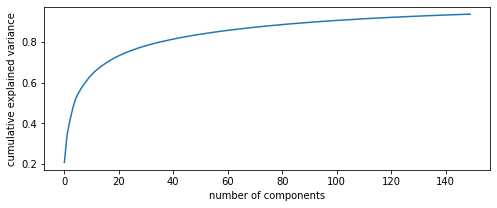

In [33]:
plt.figure(figsize = (8,3))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('number of components'); plt.ylabel('cumulative explained variance');
plt.show()

## 150-dimensional PCA reconstruction of the LFW data

La fila superior aquí muestra las imágenes de entrada, mientras que la fila inferior muestra la reconstrucción de las imágenes a partir de solo 150 de las ~3000 características iniciales. Aunque reduce la dimensionalidad de los datos en casi un factor de 20, las imágenes proyectadas contienen suficiente información para que podamos reconocer a simple vista a los individuos en la imagen.

In [34]:
components = pca.transform(faces.data)
projected = pca.inverse_transform(components)

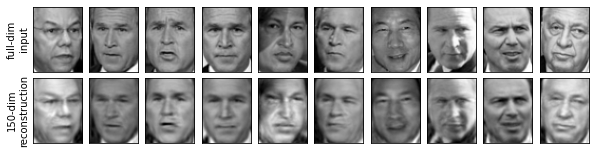

In [35]:
plot_reconstruction(faces.data, projected)

# t-Distributed Stochastic Neighbor Embedding (t-SNE)

t-SNE no trabaja con ejes como PCA, sino con **similitudes entre puntos**.

### Objetivo:

Si dos puntos son cercanos en alta dimensión deben ser cercanos en baja dimensión (intenta preservar la **estructura local**).

## Paso 1: similitud en alta dimensión

Para cada par de puntos $(i, j)$ se calcula qué tan "cercanos" son y esto se convierte en una probabilidad (se usa una distribución Gaussiana):

- puntos cercanos → alta probabilidad
- puntos lejanos → baja probabilidad

<div align="center">
<img src="img/tSNE.png" alt="" width="50%" align="center" />
</div>

## Paso 2: representar en baja dimensión

Ahora colocamos los puntos en 2D (inicialmente al azar) y calculamos nuevas probabilidades:

- qué tan cercanos están en 2D

Aquí se usa una distribución t-Student (colas largas, separa mejor).

<div align="center">
<img src="img/tStudent.jpg" alt="" width="50%" align="center" />
</div>

## Paso 3: optimización

t-SNE ajusta las posiciones de los puntos en 2D para que las probabilidades en baja dimensión sean similares a las de alta dimensión.


### ¿Cómo?

Minimizando una diferencia entre distribuciones: KL Divergence. Para eso, utiliza descenso de gradiente.

## Implicancias

t-SNE:

- mantiene puntos cercanos juntos ✔
- puede distorsionar distancias globales ❗
- NO confiar en distancias grandes

## Perplexity

Controla cuántos vecinos considera cada punto:

- baja perplexity → enfoque muy local
- alta perplexity → más global


**Regla práctica:**

- valores típicos: 5 – 50
- probar varios valores

# t-SNE for visualization: Handwritten digits

In [36]:
tsne_vis(X_digits, digits, perplexity_values=[1,2,3,4,5,10,20,30,40,50,60,70,80,90,100])

interactive(children=(Dropdown(description='Perplexity', index=7, options=(1, 2, 3, 4, 5, 10, 20, 30, 40, 50, …

## PCA vs t-SNE

| PCA | t-SNE |
|-----|------|
| Lineal | No lineal |
| Preserva varianza global | Preserva estructura local |
| Rápido | Lento |
| Interpretable | Difícil de interpretar |
| Proyección clara | Embedding complejo |